# Experiment 7 — Advanced ML Pipelines with “From Scratch” Ensembles

**Course:** Machine Learning with Python Lab
**Dataset:** Predict the Success of Bank Telemarketing — the CSV linked in *Experiment 7.pdf*
**Problem:** Predict a subscription outcome: **no → 0**, **yes → 1**.

## Objective
Build a unified date-engineering, imputation, scaling, encoding, and PCA pipeline; implement F1-macro, K-fold splitting, bootstrap sampling, and bagging manually; tune the ensemble using training-only cross-validation; and evaluate it on the untouched 30% hold-out set.

| PDF task | Marks | Notebook section |
|---|---:|---|
| 1. Load data, encode target, make a 70/30 split | 10 | Task 1 |
| 2. Advanced preprocessing and PCA (95% variance) | 25 | Task 2 |
| 3. F1-macro, K-fold, and bootstrap utilities from scratch | 20 | Task 3 |
| 4. Bagging: bootstrap, fit independent learners, vote | 30 | Task 4 |
| 5. Custom CV tuning, final training, final evaluation | 15 | Task 5 |

**What is actually from scratch?** Ensemble sampling and voting, the CV generator/loop, and F1-macro use NumPy/Pandas. `DecisionTreeClassifier` is only the permitted **base learner**. No built-in bagging classifier, `KFold`, or `GridSearchCV` is used.


In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 20)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)


NumPy: 2.2.6
Pandas: 2.3.3
scikit-learn: 1.7.2


In [2]:
# Set to "dark" for dark figures. Both palettes are selected explicitly.
CHART_THEME = "light"
if CHART_THEME not in {"light", "dark"}:
    raise ValueError("CHART_THEME must be 'light' or 'dark'.")

CHART_PALETTES = {
    "light": {
        "surface": "#fcfcfb", "ink": "#0b0b0b", "secondary": "#52514e",
        "grid": "#e1e0d9", "axis": "#c3c2b7", "series": "#2a78d6",
    },
    "dark": {
        "surface": "#1a1a19", "ink": "#f0efec", "secondary": "#c3c2b7",
        "grid": "#2c2c2a", "axis": "#383835", "series": "#3987e5",
    },
}
C = CHART_PALETTES[CHART_THEME]
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "savefig.facecolor": C["surface"], "axes.edgecolor": C["axis"],
    "text.color": C["ink"], "axes.labelcolor": C["secondary"],
    "axes.titlecolor": C["ink"], "xtick.color": C["secondary"],
    "ytick.color": C["secondary"], "grid.color": C["grid"],
    "grid.linewidth": 0.7, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})

# A single-hue magnitude ramp, not a categorical rainbow.
blue_steps = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
if CHART_THEME == "dark":
    blue_steps = list(reversed(blue_steps))
BLUE_CMAP = LinearSegmentedColormap.from_list("bank_blue", blue_steps)


## Task 1 — Data loading and initial setup (10 marks)

Load the **actual CSV linked in the PDF**, inspect its schema and missing values, map the target explicitly, and make a single reproducible **70% training / 30% hold-out validation** split. Stratification preserves the class proportions; it does not change the requested split ratio.


In [3]:
# Optional override, for example: DATA_PATH = Path("/content/train.csv")
DATA_PATH = None

if DATA_PATH is None:
    candidates = [
        Path("data/train.csv"),
        Path("train.csv"),
        Path("Exp 7/data/train.csv"),
        Path("Exp 7/train.csv"),
        Path("Machine Learning with Python Lab/Exp 7/data/train.csv"),
        Path("Predict_the_Success_of_Bank_telemarketing_train.csv"),
    ]
    DATA_PATH = next((path for path in candidates if path.is_file()), None)

if DATA_PATH is None or not Path(DATA_PATH).is_file():
    raise FileNotFoundError(
        "Cannot find the assignment CSV. Put train.csv in Exp 7/data/ "
        "or set DATA_PATH to its full path."
    )

DATA_PATH = Path(DATA_PATH)
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

TARGET_COLUMN = "target"
DATE_COLUMN = "last contact date"
required_columns = {TARGET_COLUMN, DATE_COLUMN}
if not required_columns.issubset(df.columns):
    raise ValueError(f"The assignment CSV must contain {sorted(required_columns)}.")
if df.columns.duplicated().any():
    raise ValueError("The CSV contains duplicate column names.")

print("Loaded:", DATA_PATH)
print("Shape (rows, columns):", df.shape)
print("Columns:", df.columns.tolist())
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.head())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_rows": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(2),
}))


Loaded: Exp 7\data\train.csv
Shape (rows, columns): (39211, 16)
Columns: ['last contact date', 'age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'target']
Duplicate rows: 0


,last contact date,age,job,marital,education,default,balance,housing,loan,contact,duration,campaign,pdays,previous,poutcome,target
0,2009-04-17,26,blue-collar,married,secondary,no,647,yes,no,cellular,357,2,331,1,other,no
1,2009-10-11,52,technician,married,secondary,no,553,yes,no,telephone,160,1,-1,0,NaN,no
2,2010-11-20,44,blue-collar,married,secondary,no,1397,no,no,cellular,326,1,-1,0,NaN,no
3,2009-09-01,33,admin.,married,secondary,no,394,yes,no,telephone,104,3,-1,0,NaN,no
4,2008-01-29,31,entrepreneur,single,tertiary,no,137,no,no,cellular,445,2,-1,0,NaN,no


,dtype,missing_rows,missing_percent
last contact date,object,0,0.00
age,int64,0,0.00
job,object,229,0.58
marital,object,0,0.00
education,object,1467,3.74
default,object,0,0.00
balance,int64,0,0.00
housing,object,0,0.00
loan,object,0,0.00
contact,object,10336,26.36


In [4]:
# Reject unexpected/missing labels instead of silently mapping them to class 0.
y_text = df[TARGET_COLUMN].astype("string").str.strip().str.lower()
if y_text.isna().any() or not y_text.isin(["no", "yes"]).all():
    raise ValueError("Target labels must be non-missing 'no' or 'yes'.")

X = df.drop(columns=[TARGET_COLUMN]).copy()
y = y_text.map({"no": 0, "yes": 1}).to_numpy(dtype=np.int64)

class_counts = pd.Series(y).value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({
    "label": ["no (0)", "yes (1)"],
    "rows": class_counts.to_numpy(),
    "percent": (100 * class_counts.to_numpy() / len(y)).round(2),
}))

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y,
)
assert len(X_train) + len(X_val) == len(X)
assert set(X_train.index).isdisjoint(set(X_val.index))

print("Training rows:", len(X_train))
print("Reserved hold-out rows:", len(X_val))
print("Training positive-class share:", f"{y_train.mean():.2%}")
print("The hold-out features and labels are not used for model development.")


,label,rows,percent
0,no (0),33384,85.14
1,yes (1),5827,14.86


Training rows: 27447
Reserved hold-out rows: 11764
Training positive-class share: 14.86%
The hold-out features and labels are not used for model development.


## Task 2 — Advanced preprocessing pipeline (25 marks)

**Raw dates → month and weekday → ColumnTransformer → PCA.**

- Numerical columns: training-set **median imputation**, followed by **StandardScaler**.
- Categorical columns, including the new date features: constant **`Missing`** imputation, then dense **one-hot encoding** with `handle_unknown='ignore'`.
- **`PCA(n_components=0.95, svd_solver='full')`** chooses the smallest number of components explaining at least 95% of the variance in the encoded/scaled matrix. Dense one-hot output is appropriate for this modest-width dataset and supports fractional PCA components.
- Missing or malformed dates become missing categorical features. The original date string is dropped. The meaningful `pdays = -1` sentinel is retained, not treated as an absent value.

The date transformer is stateless: it extracts calendar fields independently for each row and never learns from hold-out data.


In [5]:
def add_date_features(frame):
    """Extract categorical month and weekday; do not mutate the input."""
    result = frame.copy()
    dates = pd.to_datetime(result[DATE_COLUMN], format="%Y-%m-%d", errors="coerce")
    result["month"] = dates.dt.strftime("%m")  # strings '01', ..., '12'
    result["day_of_week"] = dates.dt.dayofweek.map({
        0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun",
    })
    return result.drop(columns=[DATE_COLUMN])


# These lists are determined from the training schema, not from validation data.
engineered_schema = add_date_features(X_train.head())
numerical_features = engineered_schema.select_dtypes(include=np.number).columns.tolist()
categorical_features = [
    column for column in engineered_schema.columns if column not in numerical_features
]
assert {"month", "day_of_week"}.issubset(categorical_features)

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
display(engineered_schema)

# Calendar correctness and malformed-date behavior.
date_example = pd.DataFrame({DATE_COLUMN: ["2009-04-17", "bad-date", None]})
date_result = add_date_features(date_example)
assert date_result.loc[0, "month"] == "04"
assert date_result.loc[0, "day_of_week"] == "Fri"
assert date_result.iloc[1:].isna().all().all()
assert DATE_COLUMN in date_example.columns  # the original frame was not changed
print("Date transformer checks passed.")


Numerical features: ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'month', 'day_of_week']


,age,job,marital,education,default,balance,housing,loan,contact,duration,campaign,pdays,previous,poutcome,month,day_of_week
15450,64,entrepreneur,divorced,secondary,no,46599,yes,yes,cellular,4174,51,126,6,failure,09,Sat
7609,45,management,married,tertiary,no,623,no,no,cellular,405,3,-1,0,NaN,09,Tue
21983,59,retired,married,secondary,no,836,yes,no,NaN,106,1,-1,0,NaN,05,Thu
13917,41,blue-collar,married,secondary,no,113,no,no,cellular,92,15,-1,0,NaN,07,Fri
20991,34,services,married,secondary,no,145,no,yes,cellular,152,2,-1,0,NaN,07,Wed


Date transformer checks passed.


In [6]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="Missing", keep_empty_features=True,
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numerical_features),
    ("categorical", categorical_transformer, categorical_features),
], remainder="drop")

preprocessing_pipeline = Pipeline([
    ("date_features", FunctionTransformer(add_date_features, validate=False)),
    ("preprocessor", preprocessor),
    ("pca", PCA(n_components=0.95, svd_solver="full")),
])

# This all-training fit is reserved for final-model training.
# CV will use separate, fresh clones fitted only on each inner training fold.
X_train_processed = preprocessing_pipeline.fit_transform(X_train)
pca = preprocessing_pipeline.named_steps["pca"]
encoded_feature_names = preprocessing_pipeline.named_steps["preprocessor"].get_feature_names_out()

feature_summary = pd.DataFrame({
    "stage": ["Raw input", "After date engineering", "After encoding/scaling", "After PCA"],
    "number_of_features": [
        X_train.shape[1], len(numerical_features) + len(categorical_features),
        len(encoded_feature_names), X_train_processed.shape[1],
    ],
})
display(feature_summary)
print("X_train_processed shape:", X_train_processed.shape)
print("Retained variance:", f"{pca.explained_variance_ratio_.sum():.2%}")
assert np.isfinite(X_train_processed).all()
assert pca.explained_variance_ratio_.sum() >= 0.95


,stage,number_of_features
0,Raw input,15
1,After date engineering,16
2,After encoding/scaling,57
3,After PCA,32


X_train_processed shape: (27447, 32)
Retained variance: 95.41%


In [7]:
# Check missing numeric values, unseen categories, and malformed dates
# using copies of TRAINING rows only.
probe = X_train.iloc[:3].copy()
probe[numerical_features[0]] = probe[numerical_features[0]].astype(float)
probe.loc[probe.index[0], numerical_features[0]] = np.nan
probe.loc[probe.index[1], categorical_features[0]] = "never_seen_job_category"
probe.loc[probe.index[2], DATE_COLUMN] = "invalid-date"
probe_processed = preprocessing_pipeline.transform(probe)

assert probe_processed.shape == (len(probe), X_train_processed.shape[1])
assert np.isfinite(probe_processed).all()
print("Pipeline robustness checks passed: missing values, unseen categories, invalid dates.")


Pipeline robustness checks passed: missing values, unseen categories, invalid dates.


,component,explained_variance_ratio,cumulative_variance_ratio
0,1,0.3327,0.3327
1,2,0.0857,0.4184
2,3,0.0570,0.4754
3,4,0.0563,0.5317
4,5,0.0367,0.5684
5,6,0.0320,0.6004
6,7,0.0313,0.6317
7,8,0.0282,0.6599
8,9,0.0273,0.6871
9,10,0.0247,0.7118


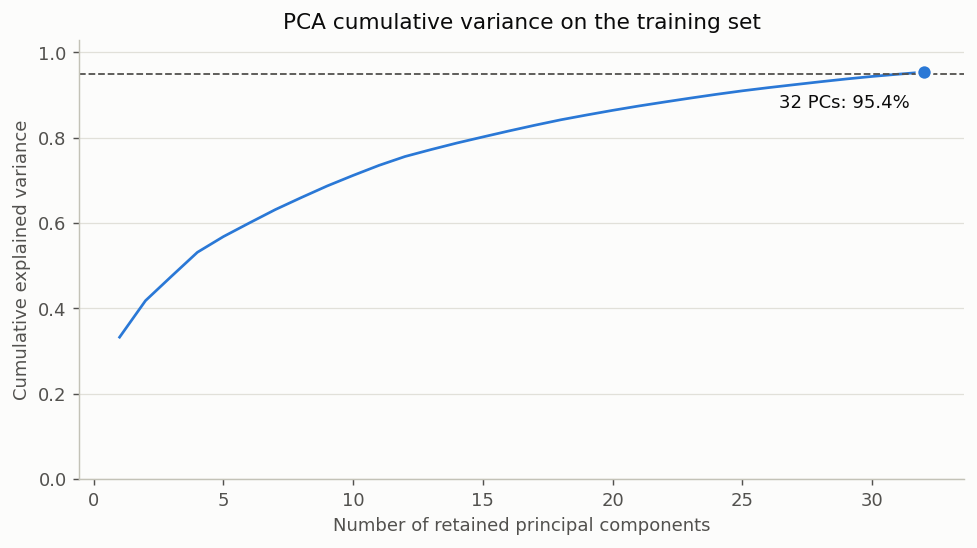

In [8]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
pca_table = pd.DataFrame({
    "component": np.arange(1, len(cumulative_variance) + 1),
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance_ratio": cumulative_variance,
})
display(pca_table.round(4))

fig, ax = plt.subplots(figsize=(7.4, 4.1), layout="constrained")
ax.plot(
    pca_table["component"], cumulative_variance, color=C["series"], linewidth=1.5,
)
ax.scatter(
    [len(cumulative_variance)], [cumulative_variance[-1]], s=70,
    color=C["series"], edgecolors=C["surface"], linewidths=1.5, zorder=3,
)
ax.axhline(0.95, color=C["secondary"], linewidth=1, linestyle="--")
ax.annotate(
    f"{len(cumulative_variance)} PCs: {cumulative_variance[-1]:.1%}",
    (len(cumulative_variance), cumulative_variance[-1]),
    xytext=(-8, -20), textcoords="offset points", ha="right", color=C["ink"],
)
ax.set(title="PCA cumulative variance on the training set",
       xlabel="Number of retained principal components", ylabel="Cumulative explained variance")
ax.set_ylim(0, 1.03)
ax.grid(axis="y")
plt.show()


## Task 3 — “From scratch” utilities (20 marks)

### 3.1 F1-macro
For each class $c \in \{0,1\}$, calculate:

$$P_c = \frac{TP_c}{TP_c+FP_c},\qquad R_c = \frac{TP_c}{TP_c+FN_c},\qquad F1_c = \frac{2P_cR_c}{P_c+R_c}.$$

A ratio with a zero denominator is defined as **0**. Return
$\mathrm{F1}_{macro} = (F1_0 + F1_1)/2$.

Both classes are always included, even if one is absent in a small test case. This is intentional; the corresponding sklearn check must use `labels=[0, 1]`.


In [9]:
def get_f1_macro(y_true, y_pred):
    """Binary macro F1 computed directly from NumPy class counts."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if y_true.ndim != 1 or y_pred.ndim != 1 or len(y_true) != len(y_pred):
        raise ValueError("y_true and y_pred must be matching one-dimensional arrays.")
    if len(y_true) == 0:
        raise ValueError("F1 cannot be calculated for empty arrays.")
    if not np.isin(y_true, [0, 1]).all() or not np.isin(y_pred, [0, 1]).all():
        raise ValueError("get_f1_macro expects binary labels 0 and 1.")

    class_f1_scores = []
    for label in (0, 1):
        tp = np.sum((y_true == label) & (y_pred == label))
        fp = np.sum((y_true != label) & (y_pred == label))
        fn = np.sum((y_true == label) & (y_pred != label))
        precision = tp / (tp + fp) if tp + fp > 0 else 0.0
        recall = tp / (tp + fn) if tp + fn > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
        class_f1_scores.append(f1)
    return float(np.mean(class_f1_scores))


f1_examples = [
    ("perfect", [0, 0, 1, 1], [0, 0, 1, 1]),
    ("mixed errors", [0, 0, 1, 1], [0, 1, 1, 1]),
    ("predict only no", [0, 0, 1, 1], [0, 0, 0, 0]),
    ("both classes wrong", [0, 0, 1, 1], [1, 1, 0, 0]),
    ("only class 0 present", [0, 0], [0, 0]),
    ("only class 1 present", [1, 1], [1, 1]),
    ("zero true positives", [1, 1], [0, 0]),
]
f1_checks = []
for name, true, predicted in f1_examples:
    scratch_score = get_f1_macro(true, predicted)
    reference_score = f1_score(true, predicted, labels=[0, 1], average="macro", zero_division=0)
    assert np.isclose(scratch_score, reference_score)
    f1_checks.append({"case": name, "scratch_F1": scratch_score, "sklearn_F1": reference_score})
display(pd.DataFrame(f1_checks).round(4))
print("All custom F1 checks passed.")


,case,scratch_F1,sklearn_F1
0,perfect,1.0000,1.0000
1,mixed errors,0.7333,0.7333
2,predict only no,0.3333,0.3333
3,both classes wrong,0.0000,0.0000
4,only class 0 present,0.5000,0.5000
5,only class 1 present,0.5000,0.5000
6,zero true positives,0.0000,0.0000


All custom F1 checks passed.


### 3.2 K-fold generator
Shuffle positional row indices with a local seeded NumPy random state, divide them into near-equal folds, and yield each fold once as the test portion. All remaining rows form its training portion. This is **plain shuffled K-fold**, not stratified K-fold, as specified in the PDF.

The small `_take_rows` helper preserves DataFrames/Series when raw data is used in leakage-free CV, and also works with processed NumPy arrays.


In [10]:
def _take_rows(data, indices):
    """Use positional indexing for either pandas or NumPy data."""
    if isinstance(data, (pd.DataFrame, pd.Series)):
        return data.iloc[indices]
    return np.asarray(data)[indices]


def _check_paired_data(X, y):
    if np.ndim(X) != 2 or np.ndim(y) != 1:
        raise ValueError("X must be two-dimensional and y one-dimensional.")
    if len(X) != len(y) or len(y) == 0:
        raise ValueError("X and y must have matching, non-zero numbers of rows.")


def my_kfold(X, y, n_splits, shuffle=True, random_state=42):
    """Yield (X_train_fold, y_train_fold, X_test_fold, y_test_fold)."""
    _check_paired_data(X, y)
    if not isinstance(n_splits, (int, np.integer)) or not 2 <= n_splits <= len(X):
        raise ValueError("n_splits must be an integer between 2 and len(X).")

    indices = np.arange(len(X))
    if shuffle:
        # Local seeded permutation: reproducible without changing global state.
        indices = np.random.RandomState(random_state).permutation(indices)
    folds = np.array_split(indices, n_splits)  # includes remainder rows

    for fold_number in range(n_splits):
        test_indices = folds[fold_number]
        train_indices = np.concatenate([
            folds[i] for i in range(n_splits) if i != fold_number
        ])
        yield (
            _take_rows(X, train_indices), _take_rows(y, train_indices),
            _take_rows(X, test_indices), _take_rows(y, test_indices),
        )


In [11]:
# Unique row IDs make overlap, coverage, and X/y alignment testable.
toy_X = np.column_stack([np.arange(11), np.arange(11) / 10])
toy_y = np.arange(11) % 2
folds_a = list(my_kfold(toy_X, toy_y, n_splits=3, random_state=42))
folds_b = list(my_kfold(toy_X, toy_y, n_splits=3, random_state=42))
seen_test_rows = []
fold_sizes = []

for a, b in zip(folds_a, folds_b):
    X_tr, y_tr, X_te, y_te = a
    train_ids = X_tr[:, 0].astype(int)
    test_ids = X_te[:, 0].astype(int)
    assert set(train_ids).isdisjoint(set(test_ids))
    assert len(X_tr) + len(X_te) == len(toy_X)
    assert np.array_equal(y_tr, train_ids % 2)
    assert np.array_equal(y_te, test_ids % 2)
    assert all(np.array_equal(left, right) for left, right in zip(a, b))
    seen_test_rows.extend(test_ids)
    fold_sizes.append(len(X_te))

assert np.array_equal(np.sort(seen_test_rows), np.arange(len(toy_X)))
assert max(fold_sizes) - min(fold_sizes) <= 1

# Confirm pandas inputs retain their types and positional alignment.
toy_frame = pd.DataFrame(toy_X, columns=["row_id", "value"], index=np.arange(100, 111))
toy_series = pd.Series(toy_y, index=toy_frame.index)
for X_tr, y_tr, X_te, y_te in my_kfold(toy_frame, toy_series, n_splits=3):
    assert isinstance(X_tr, pd.DataFrame) and isinstance(y_tr, pd.Series)
    assert X_tr.index.equals(y_tr.index) and X_te.index.equals(y_te.index)

# The exact generator also accepts the full-training processed matrix.
first_processed_fold = next(my_kfold(X_train_processed[:20], y_train[:20], n_splits=5))
assert first_processed_fold[0].shape[1] == X_train_processed.shape[1]
print("K-fold checks passed: full coverage, no overlap, remainders, reproducibility, pandas/NumPy.")
print("Toy test-fold sizes:", fold_sizes)


K-fold checks passed: full coverage, no overlap, remainders, reproducibility, pandas/NumPy.
Toy test-fold sizes: [4, 4, 3]


### 3.3 Bootstrap sample / batch generator
Sampling **with replacement** allows the same original row to appear multiple times and leaves some rows out. The optional `random_state` argument extends the PDF's three-argument interface without changing it; a seed or NumPy generator makes sampling reproducible.


In [12]:
def get_bootstrap_sample(X, y, n_samples, random_state=None):
    """Return paired rows sampled with replacement, using only NumPy/Pandas."""
    _check_paired_data(X, y)
    if not isinstance(n_samples, (int, np.integer)) or n_samples < 1:
        raise ValueError("n_samples must be a positive integer.")
    rng = np.random.default_rng(random_state)
    indices = rng.choice(len(X), size=n_samples, replace=True)
    return _take_rows(X, indices), _take_rows(y, indices)


X_batch, y_batch = get_bootstrap_sample(toy_X, toy_y, n_samples=30, random_state=42)
X_batch_repeat, y_batch_repeat = get_bootstrap_sample(toy_X, toy_y, 30, random_state=42)
assert X_batch.shape == (30, toy_X.shape[1])
assert np.array_equal(y_batch, X_batch[:, 0].astype(int) % 2)
assert len(np.unique(X_batch[:, 0])) < len(X_batch)  # replacement creates duplicates
assert np.array_equal(X_batch, X_batch_repeat)
assert np.array_equal(y_batch, y_batch_repeat)
print("Bootstrap checks passed: correct size, paired rows, duplicates, reproducibility.")
print("Original toy rows:", len(toy_X), "| Sample rows:", len(X_batch),
      "| Unique sampled rows:", len(np.unique(X_batch[:, 0])))


Bootstrap checks passed: correct size, paired rows, duplicates, reproducibility.
Original toy rows: 11 | Sample rows: 30 | Unique sampled rows: 9


## Task 4 — “From scratch” bagging classifier (30 marks)

For each of $B$ learners:
1. Draw `int(len(X) * max_samples)` training rows **with replacement**.
2. Create and train a new `DecisionTreeClassifier` on that bootstrap sample.
3. Store the trained learner in `estimators_`.

For prediction, form a vote matrix of shape `(number of rows, number of learners)`. Because the labels are binary, count votes for class 1. A strict majority predicts 1; otherwise predict 0. **Ties deterministically predict 0.**

All experiments use `max_depth=10` for each base tree and `max_samples=1.0`. A local generator controls both bootstrap draws and independent tree seeds. Calling `fit` again replaces the previous ensemble rather than appending to it.


In [13]:
class MyBaggingClassifier:
    """Binary bagging meta-estimator: manual bootstrap training and majority votes."""

    def __init__(self, base_estimator_class, n_estimators, max_samples=1.0,
                 random_state=42, base_estimator_params=None):
        if not isinstance(n_estimators, (int, np.integer)) or n_estimators < 1:
            raise ValueError("n_estimators must be a positive integer.")
        if not 0 < max_samples <= 1:
            raise ValueError("max_samples must be a fraction in (0, 1].")
        self.base_estimator_class = base_estimator_class
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.random_state = random_state
        self.base_estimator_params = dict(base_estimator_params or {})
        self.estimators_ = []

    def fit(self, X, y):
        _check_paired_data(X, y)
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if not np.isfinite(X).all():
            raise ValueError("Preprocess X before fitting: values must be finite.")
        if not np.isin(y, [0, 1]).all():
            raise ValueError("This classifier expects binary labels 0 and 1.")

        n_samples_for_bootstrap = int(len(X) * self.max_samples)
        if n_samples_for_bootstrap < 1:
            raise ValueError("max_samples produces an empty bootstrap sample.")
        self.n_features_in_ = X.shape[1]
        self.estimators_ = []
        rng = np.random.default_rng(self.random_state)

        for _ in range(self.n_estimators):
            X_batch, y_batch = get_bootstrap_sample(
                X, y, n_samples_for_bootstrap, random_state=rng,
            )
            parameters = self.base_estimator_params.copy()
            parameters["random_state"] = int(rng.integers(0, 2**31 - 1))
            estimator = self.base_estimator_class(**parameters)
            estimator.fit(X_batch, y_batch)
            self.estimators_.append(estimator)
        return self

    def predict(self, X):
        if not self.estimators_:
            raise ValueError("Fit the ensemble before calling predict.")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError("X must be 2D and have the same feature count as during fit.")
        if not np.isfinite(X).all():
            raise ValueError("Prediction features must be finite.")
        if len(X) == 0:
            return np.empty(0, dtype=np.int64)

        votes = np.column_stack([estimator.predict(X) for estimator in self.estimators_])
        votes_for_one = np.sum(votes == 1, axis=1)
        return (votes_for_one > len(self.estimators_) / 2).astype(np.int64)


In [14]:
# Small training test: independent estimators, repeat-fit reset, seeded reproducibility.
toy_bagging = MyBaggingClassifier(
    DecisionTreeClassifier, n_estimators=3, max_samples=0.8,
    random_state=42, base_estimator_params={"max_depth": 2},
)
assert toy_bagging.fit(toy_X, toy_y) is toy_bagging
toy_prediction = toy_bagging.predict(toy_X)
assert len(toy_bagging.estimators_) == 3
assert len({id(estimator) for estimator in toy_bagging.estimators_}) == 3
assert toy_prediction.shape == (len(toy_X),)
assert np.isin(toy_prediction, [0, 1]).all()
toy_bagging.fit(toy_X, toy_y)
assert len(toy_bagging.estimators_) == 3
assert np.array_equal(toy_prediction, toy_bagging.predict(toy_X))

# Constant test doubles verify the voting logic without a fitted sklearn ensemble.
class ConstantVote:
    def __init__(self, label):
        self.label = label

    def predict(self, X):
        return np.full(len(X), self.label, dtype=np.int64)


vote_test = MyBaggingClassifier(DecisionTreeClassifier, n_estimators=2)
vote_test.n_features_in_ = toy_X.shape[1]
vote_test.estimators_ = [ConstantVote(0), ConstantVote(1)]
assert np.all(vote_test.predict(toy_X) == 0)  # tied vote -> class 0
vote_test.estimators_ = [ConstantVote(1), ConstantVote(1), ConstantVote(0)]
assert np.all(vote_test.predict(toy_X) == 1)  # majority vote -> class 1
assert vote_test.predict(toy_X[:0]).shape == (0,)
print("Bagging checks passed: independent learners, fit reset, reproducibility, votes and ties.")


Bagging checks passed: independent learners, fit reset, reproducibility, votes and ties.


## Task 5 — Integration, tuning, and final evaluation (15 marks)

### 5.1 Prepare five leakage-free CV folds
Only the **70% training partition** is passed to `my_kfold`. For every fold, a fresh pipeline is fitted on its raw training rows and applied unchanged to its inner test rows. Missing-value statistics, one-hot categories, scaling parameters, and PCA components are therefore learned inside that fold.

We cache these five processed fold pairs and reuse them across hyperparameter candidates. This avoids refitting the same preprocessing repeatedly and does **not** leak between folds. Independent folds may retain different numbers of PCs.


In [15]:
N_SPLITS = 5
ESTIMATOR_COUNTS = [10, 30, 50]
BASE_TREE_PARAMETERS = {"max_depth": 10}
MAX_SAMPLES = 1.0

processed_folds = []
fold_information = []
for fold_number, (X_fold_train, y_fold_train, X_fold_test, y_fold_test) in enumerate(
    my_kfold(X_train, y_train, n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    start=1,
):
    assert set(X_fold_train.index).isdisjoint(set(X_fold_test.index))
    fold_pipeline = clone(preprocessing_pipeline)  # clone discards fitted attributes
    X_fold_train_processed = fold_pipeline.fit_transform(X_fold_train)
    X_fold_test_processed = fold_pipeline.transform(X_fold_test)
    assert fold_pipeline.named_steps["pca"].n_samples_ == len(X_fold_train)
    assert np.isfinite(X_fold_train_processed).all()
    assert np.isfinite(X_fold_test_processed).all()

    processed_folds.append((
        X_fold_train_processed, y_fold_train, X_fold_test_processed, y_fold_test,
    ))
    fold_information.append({
        "fold": fold_number,
        "train_rows": len(y_fold_train), "test_rows": len(y_fold_test),
        "train_yes_percent": 100 * y_fold_train.mean(),
        "test_yes_percent": 100 * y_fold_test.mean(),
        "PCA_features": X_fold_train_processed.shape[1],
    })

display(pd.DataFrame(fold_information).round(2))
print("Fold preprocessing finished. The 30% hold-out has not been transformed or scored.")


,fold,train_rows,test_rows,train_yes_percent,test_yes_percent,PCA_features
0,1,21957,5490,14.91,14.66,32
1,2,21957,5490,15.04,14.15,32
2,3,21958,5489,14.70,15.50,32
3,4,21958,5489,14.66,15.67,32
4,5,21958,5489,15.00,14.32,32


Fold preprocessing finished. The 30% hold-out has not been transformed or scored.


In [16]:
cv_rows = []
for n_estimators in ESTIMATOR_COUNTS:
    candidate_start = perf_counter()
    fold_scores = []
    for fold_number, (X_tr, y_tr, X_te, y_te) in enumerate(processed_folds, start=1):
        model = MyBaggingClassifier(
            DecisionTreeClassifier,
            n_estimators=n_estimators,
            max_samples=MAX_SAMPLES,
            random_state=RANDOM_STATE + fold_number,
            base_estimator_params=BASE_TREE_PARAMETERS,
        )
        model.fit(X_tr, y_tr)
        predictions = model.predict(X_te)
        score = get_f1_macro(y_te, predictions)  # custom metric, not sklearn's scorer
        fold_scores.append(score)
        print(f"n_estimators={n_estimators:2d} | fold {fold_number} | F1-macro={score:.4f}", flush=True)

    row = {"n_estimators": n_estimators}
    row.update({f"fold_{i + 1}": score for i, score in enumerate(fold_scores)})
    row["mean_F1_macro"] = float(np.mean(fold_scores))
    row["std_F1_macro"] = float(np.std(fold_scores, ddof=1))
    row["fit_and_score_seconds"] = perf_counter() - candidate_start
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))

# idxmax returns the first maximum: an exact tie chooses the smaller ensemble
# because ESTIMATOR_COUNTS is in increasing order.
best_row = cv_results.loc[cv_results["mean_F1_macro"].idxmax()]
best_n_estimators = int(best_row["n_estimators"])
print("Selected n_estimators:", best_n_estimators)
print("Best mean CV F1-macro:", f"{best_row['mean_F1_macro']:.4f}")
print("Selection used training-only CV; the hold-out did not influence it.")


n_estimators=10 | fold 1 | F1-macro=0.6426
n_estimators=10 | fold 2 | F1-macro=0.6735
n_estimators=10 | fold 3 | F1-macro=0.6836
n_estimators=10 | fold 4 | F1-macro=0.6350
n_estimators=10 | fold 5 | F1-macro=0.6598
n_estimators=30 | fold 1 | F1-macro=0.6712
n_estimators=30 | fold 2 | F1-macro=0.6843
n_estimators=30 | fold 3 | F1-macro=0.6953
n_estimators=30 | fold 4 | F1-macro=0.6605
n_estimators=30 | fold 5 | F1-macro=0.6759
n_estimators=50 | fold 1 | F1-macro=0.6696
n_estimators=50 | fold 2 | F1-macro=0.6843
n_estimators=50 | fold 3 | F1-macro=0.6935
n_estimators=50 | fold 4 | F1-macro=0.6531
n_estimators=50 | fold 5 | F1-macro=0.6741


,n_estimators,fold_1,fold_2,fold_3,fold_4,fold_5,mean_F1_macro,std_F1_macro,fit_and_score_seconds
0,10,0.6426,0.6735,0.6836,0.6350,0.6598,0.6589,0.0204,80.0254
1,30,0.6712,0.6843,0.6953,0.6605,0.6759,0.6774,0.0132,341.1612
2,50,0.6696,0.6843,0.6935,0.6531,0.6741,0.6749,0.0153,390.6023


Selected n_estimators: 30
Best mean CV F1-macro: 0.6774
Selection used training-only CV; the hold-out did not influence it.


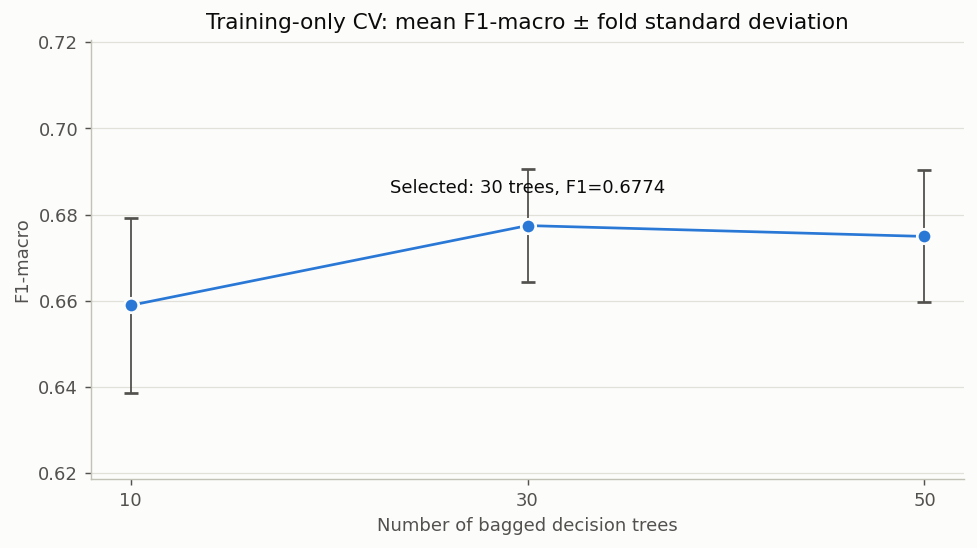

In [17]:
# Table above is the precise-value companion to this static Matplotlib chart.
fig, ax = plt.subplots(figsize=(7.4, 4.1), layout="constrained")
ax.errorbar(
    cv_results["n_estimators"], cv_results["mean_F1_macro"],
    yerr=cv_results["std_F1_macro"], fmt="o-", color=C["series"],
    ecolor=C["secondary"], linewidth=1.5, elinewidth=1, capsize=4,
    markersize=8, markeredgecolor=C["surface"], markeredgewidth=1.5,
)
ax.annotate(
    f"Selected: {best_n_estimators} trees, F1={best_row['mean_F1_macro']:.4f}",
    (best_n_estimators, best_row["mean_F1_macro"]),
    xytext=(0, 18), textcoords="offset points", ha="center", color=C["ink"],
)
ax.set_xticks(ESTIMATOR_COUNTS)
ax.set(title="Training-only CV: mean F1-macro ± fold standard deviation",
       xlabel="Number of bagged decision trees", ylabel="F1-macro")
lower = (cv_results["mean_F1_macro"] - cv_results["std_F1_macro"]).min()
upper = (cv_results["mean_F1_macro"] + cv_results["std_F1_macro"]).max()
ax.set_ylim(max(0, lower - 0.02), min(1, upper + 0.03))
ax.grid(axis="y")
plt.show()


**Reading the CV results:** the selected value maximizes mean F1-macro, not accuracy or hold-out performance. Error bars show the **standard deviation across five folds**, not a confidence interval. The line-chart y-axis is zoomed to make small differences readable; exact scores are in the table. Small changes across candidates should not be interpreted as strong statistical evidence that one ensemble is universally best.

### 5.2 Train the final model
With the hyperparameter fixed, train a new ensemble on **all `X_train_processed` and `y_train`**. The full-training preprocessing fit from Task 2 is the one used by this final model.


In [18]:
final_model = MyBaggingClassifier(
    DecisionTreeClassifier,
    n_estimators=best_n_estimators,
    max_samples=MAX_SAMPLES,
    random_state=RANDOM_STATE,
    base_estimator_params=BASE_TREE_PARAMETERS,
)
final_training_start = perf_counter()
final_model.fit(X_train_processed, y_train)
final_fit_seconds = perf_counter() - final_training_start
assert len(final_model.estimators_) == best_n_estimators

# Fixed comparison model for context, not another hyperparameter search.
single_tree = DecisionTreeClassifier(**BASE_TREE_PARAMETERS, random_state=RANDOM_STATE)
single_tree.fit(X_train_processed, y_train)

print("Final ensemble size:", len(final_model.estimators_))
print("Final training rows:", len(y_train))
print("Bootstrap rows per learner:", int(len(y_train) * MAX_SAMPLES))
print("Final ensemble fit time:", f"{final_fit_seconds:.2f} seconds")


Final ensemble size: 30
Final training rows: 27447
Bootstrap rows per learner: 27447
Final ensemble fit time: 61.68 seconds


### 5.3 Final evaluation on the reserved 30% hold-out
**This is the first step that transforms or scores the hold-out.** Apply the already-fitted full-training pipeline without refitting anything, predict with the final ensemble, calculate the custom F1-macro, and print sklearn's detailed classification report.

For context, report two fixed baselines on the same hold-out: an always-`no` predictor and one depth-10 decision tree. These comparisons are reporting only; no tuning is performed after viewing hold-out scores.


In [19]:
X_val_processed = preprocessing_pipeline.transform(X_val)
assert X_val_processed.shape[1] == X_train_processed.shape[1]
assert np.isfinite(X_val_processed).all()

y_val_pred = final_model.predict(X_val_processed)
final_f1_macro = get_f1_macro(y_val, y_val_pred)
reference_f1_macro = f1_score(y_val, y_val_pred, labels=[0, 1], average="macro", zero_division=0)
assert np.isclose(final_f1_macro, reference_f1_macro)

print("X_val_processed shape:", X_val_processed.shape)
print("FINAL HOLD-OUT F1-MACRO (FROM SCRATCH):", f"{final_f1_macro:.4f}")
print("\nClassification report — selected bagging ensemble\n")
print(classification_report(
    y_val, y_val_pred, labels=[0, 1], target_names=["no (0)", "yes (1)"],
    digits=4, zero_division=0,
))

holdout_predictions = {
    "Always no": np.zeros_like(y_val),
    "Single decision tree (depth 10)": single_tree.predict(X_val_processed),
    f"Custom bagging ({best_n_estimators} trees)": y_val_pred,
}
final_results = pd.DataFrame([
    {
        "model": name,
        "F1_macro": get_f1_macro(y_val, predictions),
        "accuracy": accuracy_score(y_val, predictions),
    }
    for name, predictions in holdout_predictions.items()
])
display(final_results.round(4))


X_val_processed shape: (11764, 32)
FINAL HOLD-OUT F1-MACRO (FROM SCRATCH): 0.6889

Classification report — selected bagging ensemble

              precision    recall  f1-score   support

      no (0)     0.8962    0.9564    0.9253     10016
     yes (1)     0.5939    0.3656    0.4525      1748

    accuracy                         0.8686     11764
   macro avg     0.7451    0.6610    0.6889     11764
weighted avg     0.8513    0.8686    0.8551     11764



,model,F1_macro,accuracy
0,Always no,0.4599,0.8514
1,Single decision tree (depth 10),0.6871,0.8581
2,Custom bagging (30 trees),0.6889,0.8686


,Predicted no (0),Predicted yes (1)
Actual no (0),9579,437
Actual yes (1),1109,639


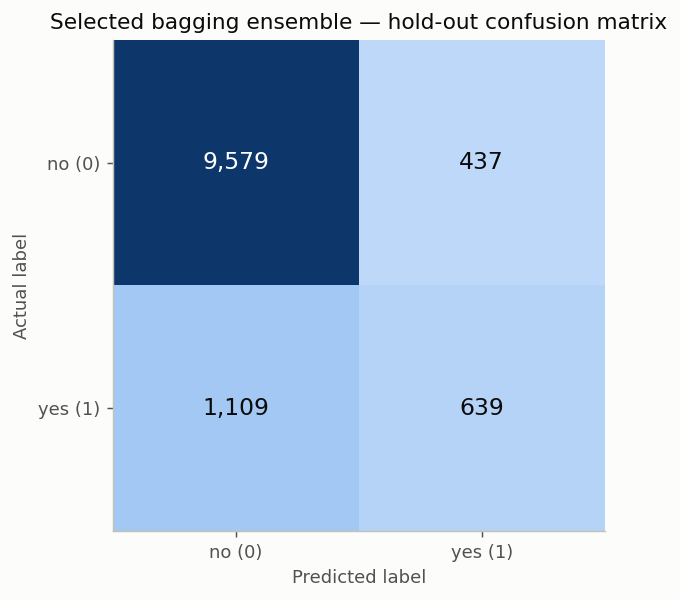

TN: 9579 | FP: 437 | FN: 1109 | TP: 639


In [20]:
cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
cm_table = pd.DataFrame(cm, index=["Actual no (0)", "Actual yes (1)"],
                        columns=["Predicted no (0)", "Predicted yes (1)"])
display(cm_table)

fig, ax = plt.subplots(figsize=(5.8, 4.5), layout="constrained")
image = ax.imshow(cm, cmap=BLUE_CMAP, vmin=0, vmax=max(1, cm.max()))
for i in range(2):
    for j in range(2):
        # Choose readable text against the actual color of each cell.
        rgb = np.asarray(image.cmap(image.norm(cm[i, j])))[:3]
        linear_rgb = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
        luminance = float(linear_rgb @ np.array([0.2126, 0.7152, 0.0722]))
        text_color = "#ffffff" if 1.05 / (luminance + 0.05) >= 4.5 else "#0b0b0b"
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13, color=text_color)
ax.set_xticks([0, 1], ["no (0)", "yes (1)"])
ax.set_yticks([0, 1], ["no (0)", "yes (1)"])
ax.set(xlabel="Predicted label", ylabel="Actual label",
       title="Selected bagging ensemble — hold-out confusion matrix")
ax.grid(False)
plt.show()

print("TN:", cm[0, 0], "| FP:", cm[0, 1], "| FN:", cm[1, 0], "| TP:", cm[1, 1])


## Conclusion and report-ready summary

The experiment combines a multi-stage sklearn preprocessing pipeline with a genuinely custom bagging meta-estimator. Calendar features are categorical, missing values are imputed inside the appropriate training scope, and PCA retains at least 95% of the variance of the preprocessed matrix.

The main implementation challenge is **correct separation of training scopes**: preprocessing must be refitted inside CV folds, bootstrap draws must stay inside each fold's training data, and the 30% hold-out must not participate in selecting the number of learners. Reproducible random sampling and an explicit tie rule make the custom ensemble repeatable.

F1-macro gives both target classes equal weight, unlike accuracy. The measured CV winner is the best candidate in this particular experiment, not proof that its tree count is optimal for every dataset. PCA is also a required experimental choice; decision trees do not inherently require scaling or PCA, and transformed components reduce direct feature interpretability.

The next cell summarizes **actual computed results**, so it remains correct after rerunning the notebook rather than relying on manually typed performance numbers.


In [21]:
majority_f1 = float(final_results.loc[final_results["model"] == "Always no", "F1_macro"].iloc[0])
single_tree_f1 = float(final_results.loc[
    final_results["model"] == "Single decision tree (depth 10)", "F1_macro",
].iloc[0])

print("EXPERIMENT 7 — MEASURED SUMMARY")
print("=" * 58)
print(f"Dataset: {len(df):,} rows, {X.shape[1]} original input features")
print(f"Training / hold-out rows: {len(y_train):,} / {len(y_val):,}")
print(f"Encoded feature count before PCA: {len(encoded_feature_names)}")
print(f"Final PCA feature count: {X_train_processed.shape[1]}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")
print(f"Selected ensemble: {best_n_estimators} trees, max_depth=10, max_samples={MAX_SAMPLES}")
print(f"Best five-fold CV F1-macro: {best_row['mean_F1_macro']:.4f}")
print(f"Final 30% hold-out F1-macro: {final_f1_macro:.4f}")
print(f"Always-no baseline F1-macro: {majority_f1:.4f}")
print(f"Single-tree baseline F1-macro: {single_tree_f1:.4f}")
print(f"Bagging minus always-no baseline: {final_f1_macro - majority_f1:+.4f}")
print(f"Bagging minus single-tree baseline: {final_f1_macro - single_tree_f1:+.4f}")
print("\nAll utility assertions, pipeline checks, and the final custom/sklearn F1 agreement passed.")


EXPERIMENT 7 — MEASURED SUMMARY
Dataset: 39,211 rows, 15 original input features
Training / hold-out rows: 27,447 / 11,764
Encoded feature count before PCA: 57
Final PCA feature count: 32
Variance retained: 95.41%
Selected ensemble: 30 trees, max_depth=10, max_samples=1.0
Best five-fold CV F1-macro: 0.6774
Final 30% hold-out F1-macro: 0.6889
Always-no baseline F1-macro: 0.4599
Single-tree baseline F1-macro: 0.6871
Bagging minus always-no baseline: +0.2291
Bagging minus single-tree baseline: +0.0018

All utility assertions, pipeline checks, and the final custom/sklearn F1 agreement passed.
